# **2. Motivos de Cartões e VAR: Embeddings, Grupos Semânticos e Resultados**

Responsabilidade deste notebook:

- carregar `data/processed/card_reasons.csv` e `data/processed/delay_reasons.csv`, gerados no notebook 1;
- consolidar as justificativas livres de cartões e explorar sua distribuição inicial;
- gerar embeddings, rodar BERTopic em duas passagens e fine-tunar o modelo a partir dos clusters da primeira passagem;
- rotular os clusters finais em grupos semânticos de motivos de cartões;
- produzir tabelas e gráficos de resultados gerais, por time e por árbitro;
- identificar menções textuais a VAR nos motivos de atraso/acréscimos e salvar os artefatos finais.


## **1. Bibliotecas**

Além das dependências de manipulação de dados e visualização, este notebook usa:

- `sentence-transformers` para gerar embeddings semânticos;
- `BERTopic` e `UMAP` para agrupar e explorar textos;
- `scikit-learn` para K-means, Silhouette Score e similaridade de cosseno.

In [1]:
import re
import shutil
import unicodedata
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sentence_transformers import models as st_models
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 220)
plt.style.use("seaborn-v0_8-whitegrid")

/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_36169/3959670724.py:12: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import models as st_models


## **2. Configuração**

Define caminhos, hiperparâmetros do modelo e limites de exibição para as tabelas comparativas. O modelo fine-tunado é reutilizado quando já existe em `models/`, evitando treinar novamente em execuções comuns.


In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
VIZ_PATH = PROJECT_ROOT / "viz"
OUTPUT_DIR = PROCESSED_PATH / "semantic_reasons"
CARD_OUTPUT_DIR = OUTPUT_DIR / "card_reasons"
DELAY_OUTPUT_DIR = OUTPUT_DIR / "delay_reasons"

CARD_REASONS_PATH = PROCESSED_PATH / "card_reasons.csv"
DELAY_REASONS_PATH = PROCESSED_PATH / "delay_reasons.csv"

for directory in [MODELS_DIR, OUTPUT_DIR, CARD_OUTPUT_DIR, DELAY_OUTPUT_DIR, VIZ_PATH]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
FINETUNED_MODEL_DIR = MODELS_DIR / "football_card_reason_mpnet_two_pass"
ENCODE_PREFIX_PASSAGE = ""
ENCODE_PREFIX_QUERY   = ""

RUN_FINE_TUNING = True
RETRAIN_FINETUNED_MODEL = False
USE_FINETUNED_IF_AVAILABLE = True
FINETUNE_EPOCHS = 1
FINETUNE_BATCH_SIZE = 32
MAX_TEXTS_PER_GROUP_FOR_FINETUNE = 220
MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE = 450

CARD_MIN_TOPIC_SIZE = 45
DELAY_MIN_TOPIC_SIZE = 35
BERTOPIC_NGRAM_RANGE = (1, 3)

CARD_TEXT_COLUMN = "card_reason_text"
CARD_TEXT_KEY_COLUMN = "card_reason_text_key"
DELAY_TEXT_COLUMN = "delay_reason_clean"

TOP_N_CARD_TEXTS = 15
TOP_N_TEAMS = 15
TOP_N_REFEREES = 15

def save_plot(fig, filename: str) -> None:
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches="tight")

## **3. Carregamento dos Dados Limpos**

Os dois arquivos de entrada vêm do notebook 1. Para cartões, o texto usado no modelo é apenas `reason`, que corresponde à justificativa livre escrita pelo árbitro. Para atrasos/acréscimos, o texto usado é `delay_reason`.


In [3]:
REQUIRED_CARD_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro",
    "card_type", "team", "minute", "half", "reason", "reason_key",
}
REQUIRED_DELAY_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro", "delay_reason",
}

cards = pd.read_csv(CARD_REASONS_PATH, keep_default_na=False)
delays = pd.read_csv(DELAY_REASONS_PATH, keep_default_na=False)

missing_cards = REQUIRED_CARD_COLUMNS.difference(cards.columns)
missing_delays = REQUIRED_DELAY_COLUMNS.difference(delays.columns)
if missing_cards:
    raise ValueError(f"Colunas ausentes em {CARD_REASONS_PATH.name}: {sorted(missing_cards)}")
if missing_delays:
    raise ValueError(f"Colunas ausentes em {DELAY_REASONS_PATH.name}: {sorted(missing_delays)}")

cards.head(3)

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key
0,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Figueirense,7,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
1,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Guarani,15,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.


In [4]:
def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.casefold()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

cards[CARD_TEXT_COLUMN] = cards["reason"].fillna("").astype(str).str.strip()
cards[CARD_TEXT_KEY_COLUMN] = cards[CARD_TEXT_COLUMN].map(normalize_text)
cards = cards[cards[CARD_TEXT_KEY_COLUMN].ne("")].reset_index(drop=True)

delays[DELAY_TEXT_COLUMN] = delays["delay_reason"].fillna("").astype(str).str.strip()
delays[DELAY_TEXT_COLUMN] = delays[DELAY_TEXT_COLUMN].where(delays[DELAY_TEXT_COLUMN].ne(""), "n/a")
delays["delay_reason_key"] = delays[DELAY_TEXT_COLUMN].map(normalize_text)

pd.Series({
    "card_rows": len(cards),
    "unique_card_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
    "delay_rows": len(delays),
    "unique_delay_reason_texts": delays["delay_reason_key"].nunique(),
    "delay_na": delays[DELAY_TEXT_COLUMN].eq("n/a").sum(),
})

card_rows                    25752
unique_card_reason_texts      6940
delay_rows                    5663
unique_delay_reason_texts     3765
delay_na                        52
dtype: int64

## **4. Leitura Inicial dos Cartões**

Antes de usar embeddings, vale medir o volume por ano, tipo de cartão e justificativas mais frequentes. Esta etapa ajuda a separar padrões muito repetidos de textos raros que tendem a virar outliers no HDBSCAN.


In [5]:
card_dataset_summary = pd.Series({
    "cards": len(cards),
    "yellow_cards": int(cards["card_type"].eq("yellow").sum()),
    "red_cards": int(cards["card_type"].eq("red").sum()),
    "teams": cards["team"].nunique(),
    "referees": cards["arbitro"].nunique(),
    "unique_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
})
card_dataset_summary

cards                  25752
yellow_cards           24573
red_cards               1179
teams                    248
referees                 173
unique_reason_texts     6940
dtype: int64

In [6]:
card_by_year_type = pd.crosstab(cards["year"], cards["card_type"])
card_by_year_type

card_type,red,yellow
year,,
2020,197,3692
2021,170,3603
2022,180,3842
2023,174,3868
2024,187,4066
2025,184,3895
2026,87,1607


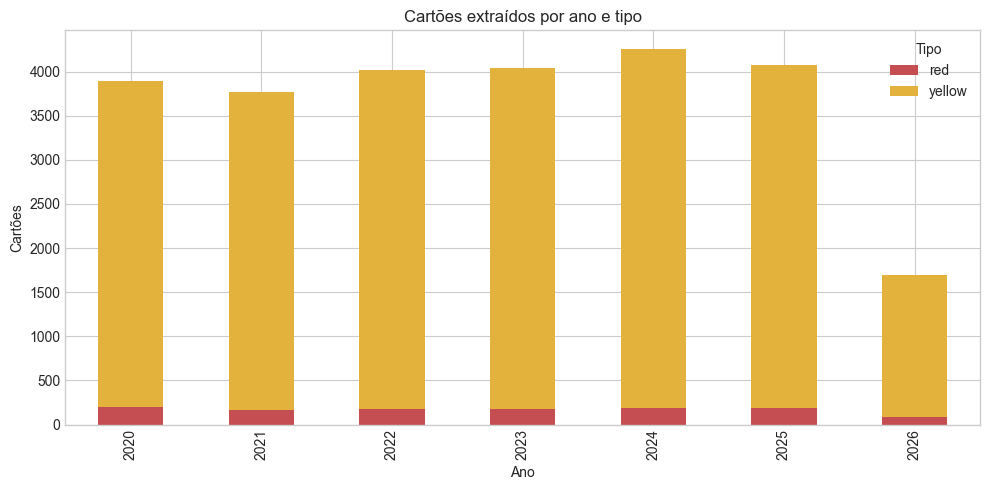

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = {"yellow": "#E3B23C", "red": "#C44E52"}
card_by_year_type.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[colors.get(column, "#4C78A8") for column in card_by_year_type.columns],
)
ax.set_title("Cartões extraídos por ano e tipo")
ax.set_xlabel("Ano")
ax.set_ylabel("Cartões")
ax.legend(title="Tipo")
plt.tight_layout()
save_plot(fig, "cards_by_year_type.png")
plt.show()

In [8]:
card_text_counts = (
    cards.groupby(CARD_TEXT_KEY_COLUMN)
    .agg(
        text_for_embedding=(CARD_TEXT_COLUMN, "first"),
        n_events=(CARD_TEXT_COLUMN, "size"),
        n_yellow=("card_type", lambda values: (values == "yellow").sum()),
        n_red=("card_type", lambda values: (values == "red").sum()),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
    .reset_index(drop=True)
)

card_texts = card_text_counts["text_for_embedding"].tolist()
card_text_counts.head(25)

,card_reason_text_key,text_for_embedding,n_events,n_yellow,n_red
0,por calcar seu adversario de maneira temeraria na disputa de bola,Por calçar seu adversário de maneira temerária na disputa de bola.,500,500,0
1,por cometer uma falta tatica impedindo um ataque promissor,"Por cometer uma falta tática, impedindo um ataque promissor.",410,410,0
2,por retardar o reinicio de jogo,Por retardar o reinicio de jogo,333,333,0
3,cometer uma falta tatica para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,285,284,1
4,por cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,248,247,1
5,por calcar seu adversario de maneira temeraria na disputa da bola,"Por calçar seu adversário de maneira temerária, na disputa da bola",236,236,0
6,por calcar seu adversario de forma temeraria na disputa de bola,Por calçar seu adversário de forma temerária na disputa de bola.,228,228,0
7,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,224,223,1
8,por reclamar contra as decisoes da arbitragem,Por reclamar contra as decisões da arbitragem.,202,202,0
9,por impedir um ataque promissor,Por impedir um ataque promissor.,202,202,0


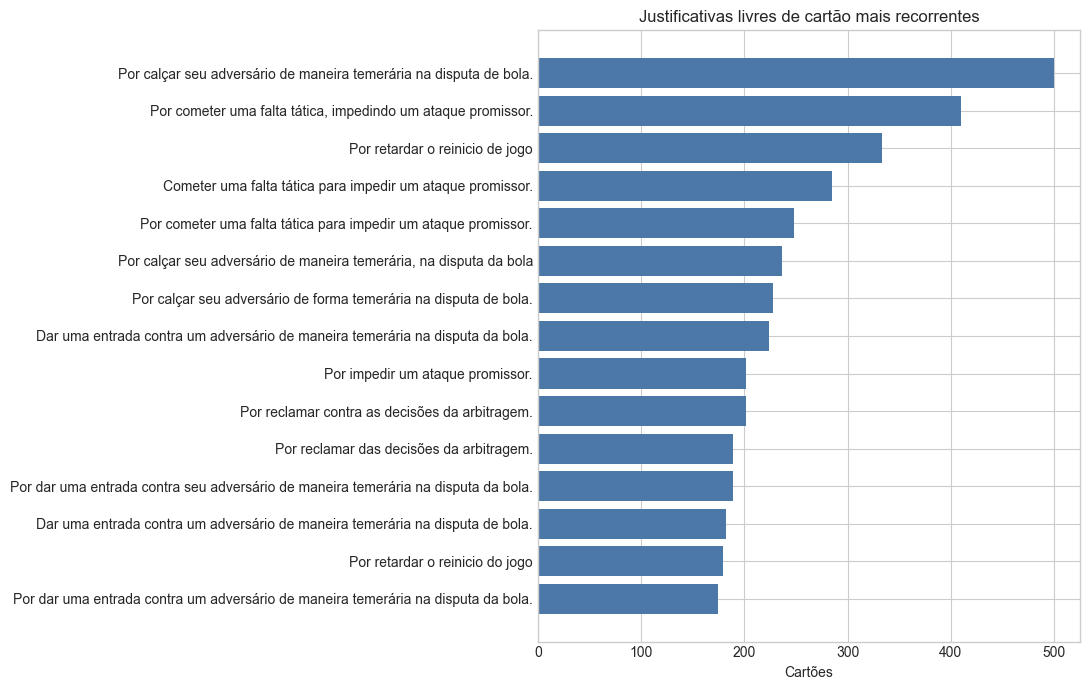

In [9]:
plot_top_texts = card_text_counts.head(TOP_N_CARD_TEXTS).sort_values("n_events")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(plot_top_texts["text_for_embedding"], plot_top_texts["n_events"], color="#4C78A8")
ax.set_title("Justificativas livres de cartão mais recorrentes")
ax.set_xlabel("Cartões")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "top_card_reason_texts.png")
plt.show()

## **5. Funções de Tópicos e Embeddings**

Os helpers abaixo padronizam a criação do BERTopic, a sumarização dos clusters e a extração de exemplos por tópico. Eles são usados tanto na primeira quanto na segunda passagem do modelo.


In [10]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "apos", "ate", "contra", "durante", "forma", "maneira", "motivo", "pela", "pelo", "pelas", "pelos",
    "num", "numa", "ter", "tendo", "dado", "haver", "havendo", "advertido", "advertida", "advertir",
    "adversario", "adversaria", "atleta", "jogador", "jogadora", "sr", "sra", "numero", "n", "equipe",
    "bola", "campo", "disputa", "jogada", "jogo", "partida", "seu", "sua", "seus", "suas", "foi", "foram",
    "acrescimo", "acrescimos", "devido", "inicio", "reinicio", "tempo", "minuto", "minutos", "jogadores",
}

def make_topic_model(min_topic_size: int) -> BERTopic:
    vectorizer_model = CountVectorizer(
        stop_words=list(PORTUGUESE_STOPWORDS),
        ngram_range=BERTOPIC_NGRAM_RANGE,
        min_df=2,
    )
    umap_model = umap.UMAP(min_dist=0.0, random_state=RANDOM_STATE)
    return BERTopic(
        language="multilingual",
        embedding_model=None,
        umap_model=umap_model,
        vectorizer_model=vectorizer_model,
        min_topic_size=min_topic_size,
        calculate_probabilities=False,
        verbose=False,
    )

def topic_words(topic_model: BERTopic, topic_id: int, top_n: int = 8) -> str:
    if topic_id == -1:
        return "outliers"
    words = topic_model.get_topic(topic_id) or []
    return ", ".join(word for word, _ in words[:top_n])

def build_topic_summary(topic_model: BERTopic, text_counts: pd.DataFrame, topic_col: str) -> pd.DataFrame:
    topic_info = topic_model.get_topic_info().rename(columns={"Topic": topic_col})
    event_counts = (
        text_counts.groupby(topic_col)
        .agg(
            n_unique_texts=("text_for_embedding", "size"),
            n_events=("n_events", "sum"),
        )
        .reset_index()
    )
    summary = topic_info.merge(event_counts, on=topic_col, how="left")
    summary["top_terms"] = summary[topic_col].map(lambda topic_id: topic_words(topic_model, int(topic_id)))
    return summary.sort_values("n_events", ascending=False).reset_index(drop=True)

def top_examples_by_topic(text_counts: pd.DataFrame, topic_col: str, top_n: int = 5) -> pd.DataFrame:
    columns = [topic_col, "n_events", "text_for_embedding"]
    return (
        text_counts.sort_values([topic_col, "n_events"], ascending=[True, False])
        .groupby(topic_col)
        .head(top_n)
        [columns]
        .reset_index(drop=True)
    )

## **6. Exploração Temática com BERTopic**

Esta etapa usa o modelo base para gerar embeddings e o BERTopic para inspecionar a estrutura temática do corpus de cartões. A análise é **puramente exploratória** — serve para entender quantos e quais padrões semânticos existem nos dados, mas **não** é usada para gerar os pares de fine-tuning.

A seleção do número de clusters para o fine-tuning é feita de forma independente na próxima seção, via critério estatístico (Silhouette Score) sobre o espaço completo de 1024 dimensões.

In [11]:
def load_embedding_model(model_name_or_path) -> SentenceTransformer:
    path = str(model_name_or_path)
    try:
        model = SentenceTransformer(path)
        print(f"[OK] SentenceTransformer: {path}")
        return model
    except Exception:
        word_model = st_models.Transformer(path, max_seq_length=256)
        pooling = st_models.Pooling(
            word_model.get_word_embedding_dimension(),
            pooling_mode_mean_tokens=True,
        )
        model = SentenceTransformer(modules=[word_model, pooling])
        print(f"[OK] Transformer + mean pooling: {path}")
        return model

def model_dir_ready(path: Path) -> bool:
    return (path / "modules.json").exists()

base_model = load_embedding_model(MODEL_NAME)

base_card_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
base_card_embeddings = np.asarray(base_card_embeddings)
print(f"Embeddings base: {base_card_embeddings.shape}")

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 8346.89it/s]


[OK] SentenceTransformer: intfloat/multilingual-e5-large


Batches: 100%|██████████| 109/109 [00:37<00:00,  2.90it/s]

Embeddings base: (6940, 1024)


In [12]:
card_topic_model_pass1 = make_topic_model(CARD_MIN_TOPIC_SIZE)
card_topics_pass1, _ = card_topic_model_pass1.fit_transform(card_texts, embeddings=base_card_embeddings)
card_text_counts["bertopic_topic_pass1"] = card_topics_pass1

pass1_counts = card_text_counts.rename(columns={"bertopic_topic_pass1": "bertopic_topic"})
pass1_summary = build_topic_summary(card_topic_model_pass1, pass1_counts, "bertopic_topic")
pass1_summary = pass1_summary.rename(columns={"bertopic_topic": "bertopic_topic_pass1"})

print(f"Pass 1 — clusters encontrados: {pass1_summary['bertopic_topic_pass1'].ne(-1).sum()}")
pass1_summary.head(20)

Pass 1 — clusters encontrados: 38


,bertopic_topic_pass1,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,0,1014,0_arbitragem_decisões_decisões arbitragem_reclamar,"[arbitragem, decisões, decisões arbitragem, reclamar, desaprovar, gestos, palavras, acintosa, decisão, protestar]","[Por reclamar acinstosamente contra as decisões da arbitragem., Por reclamar persistentimente contra as decisões da arbitragem., Reclamar contras decisões da arbitragem.]",1014,4036,"arbitragem, decisões, decisões arbitragem, reclamar, desaprovar, gestos, palavras, acintosa"
1,9,154,9_calçar_temerária calçar_calçar adversário temerária_adversário temerária calçar,"[calçar, temerária calçar, calçar adversário temerária, adversário temerária calçar, calçar adversário, temerária calçar adversário, adversário temerária, temerária, adversário, calçar temerária]","[Por calçar o adversário de maneira temerária na disputa de bola., Por calçar o seu adversário de forma temerária na disputa de bola., Ao calçar seu adversário de maneira temerária na disputa de bola.]",154,2499,"calçar, temerária calçar, calçar adversário temerária, adversário temerária calçar, calçar adversário, temerária calçar adversário, adversário temerária, temerária"
2,8,185,8_entrada_dar entrada_entrada temerária_entrada temerária adversário,"[entrada, dar entrada, entrada temerária, entrada temerária adversário, dar entrada temerária, adversário dar entrada, dar, temerária dar entrada, entrada adversário, temerária adversário]","[Por dar uma entrada de maneira temerária contra o seu adversário na disputa de bola., Por dar uma entrada temerária em seu adversário na disputa da bola., Por dar uma entrada de maneira temerária em um adversário na...",185,2442,"entrada, dar entrada, entrada temerária, entrada temerária adversário, dar entrada temerária, adversário dar entrada, dar, temerária dar entrada"
3,-1,731,-1_adversário_antidesportiva_desrespeito_segurar,"[adversário, antidesportiva, desrespeito, segurar, gol, conduta, falta, conduta antidesportiva, segurar adversário, temerária]","[Por segurar seu adversário de forma temerária na disputa de bola., Por segurar seu adversário de forma temerária, na disputa da bola., Advertido por cometer falta tática impedindo ataque promissor.]",731,1958,outliers
4,2,704,2_retardar_reinício_longe_retardar reinício,"[retardar, reinício, longe, retardar reinício, chutar, tiro, chutar longe, cobrança, tiro meta, meta]","[Retardar o reinício na cobrança do tiro de meta, Por retardar o reinício do jogo ao chutar a bola para longe com o jogo paralisado, Por retardar o reinício de jogo ao chutar a bola para longe.]",704,1932,"retardar, reinício, longe, retardar reinício, chutar, tiro, chutar longe, cobrança"
5,7,203,7_dar entrada_entrada_dar_temerária dar entrada,"[dar entrada, entrada, dar, temerária dar entrada, entrada temerária, dar entrada adversário, dar entrada temerária, adversário dar entrada, entrada adversário, entrada adversário temerária]","[Dar uma entrada de maneira temerária contra seu adversário na disputa de bola., Dar uma entrada temerária em um adversário na disputa de bola., Dar uma entrada temerária contra o adversário na disputa de bola.]",203,1728,"dar entrada, entrada, dar, temerária dar entrada, entrada temerária, dar entrada adversário, dar entrada temerária, adversário dar entrada"
6,1,792,1_cartão_expulso_segundo_informo,"[cartão, expulso, segundo, informo, após, atingido, amarelo, seguintes, atendimento, vermelho]","[Expulso com cartão vermelho direto por dar uma entrada em seu adversário de numero 30 sr, lucas evangelista santana de oliveira, com o uso de força excessiva na disputa de bola. informo que o atleta atingido recebeu...",792,1086,"cartão, expulso, segundo, informo, após, atingido, amarelo, seguintes"
7,15,100,15_calçar_temerária calçar_adversário temerária calçar_calçar adversário,"[calçar, temerária calçar, adversário temerária calçar, calçar adversário, calçar adversário temerária, temerária calçar adversário, adversár

## **7. Fine-Tuning com K-means no Espaço Completo**

Em vez dos clusters do BERTopic (que opera após compressão UMAP para 5 dimensões), os pares de treino são gerados via **K-means aplicado diretamente sobre os embeddings de 1024 dimensões**.

**Por que K-means no espaço completo é mais defensável:**
- **Sem perda de informação**: opera sem compressão dimensional
- **Sem outliers**: 100% dos textos geram pares, contra ~10–15% descartados pelo HDBSCAN
- **K determinado automaticamente**: testamos um intervalo de valores e selecionamos o K que maximiza o Silhouette Score — critério padrão na literatura de clustering, sem decisão manual

O método do cotovelo (inércia) é exibido como visualização complementar. O cap por cluster (`MAX_TEXTS_PER_GROUP_FOR_FINETUNE`, `MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE`) garante contribuição equilibrada de todos os clusters ao gradiente de treino.

In [13]:
def find_elbow(ks: list, inertias: list) -> int:
    ks_a = np.array(ks, dtype=float)
    in_a = np.array(inertias, dtype=float)
    ks_n = (ks_a - ks_a.min()) / (ks_a.max() - ks_a.min())
    in_n = (in_a - in_a.min()) / (in_a.max() - in_a.min())
    coords = np.column_stack([ks_n, in_n])
    line = coords[-1] - coords[0]
    dists = np.abs(np.cross(line / np.linalg.norm(line), coords - coords[0]))
    return int(ks_a[np.argmax(dists)])

def build_pairs_from_labels(
    text_counts: pd.DataFrame,
    labels: np.ndarray,
    max_texts: int = MAX_TEXTS_PER_GROUP_FOR_FINETUNE,
    max_pairs: int = MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE,
    prefix: str = "",
) -> list[dict]:
    df = text_counts.copy()
    df["_label"] = labels
    pairs: list[dict] = []
    for _, group in df.groupby("_label"):
        texts = (
            group.sort_values("n_events", ascending=False)["text_for_embedding"]
            .dropna().astype(str).str.strip()
            .loc[lambda s: s.ne("")]
            .drop_duplicates()
            .head(max_texts)
            .tolist()
        )
        pairs.extend(
            {"anchor": prefix + a, "positive": prefix + b}
            for a, b in list(combinations(texts, 2))[:max_pairs]
        )
    return pairs

K_RANGE = list(range(20, 105, 5))
inertias_list: list[float] = []
silhouettes_list: list[float] = []

print("Buscando K ótimo (K-means no espaço completo de embeddings)...")
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lbl = km.fit_predict(base_card_embeddings)
    inertias_list.append(float(km.inertia_))
    sil = silhouette_score(base_card_embeddings, lbl, sample_size=3000, random_state=RANDOM_STATE)
    silhouettes_list.append(float(sil))
    print(f"  K={k:3d} | inércia={km.inertia_:,.0f} | silhouette={sil:.4f}")

best_k   = K_RANGE[int(np.argmax(silhouettes_list))]
elbow_k  = find_elbow(K_RANGE, inertias_list)
print(f"\nK selecionado (silhouette máximo): {best_k}")
print(f"K do cotovelo (referência visual):  {elbow_k}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_RANGE, inertias_list, marker="o", color="#4C78A8")
axes[0].axvline(best_k,  color="#E45756", linestyle="--", label=f"K={best_k} (silhouette)")
axes[0].axvline(elbow_k, color="#72B7B2", linestyle=":",  label=f"K={elbow_k} (cotovelo)")
axes[0].set_title("Método do Cotovelo — Inércia")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inércia")
axes[0].legend()
axes[1].plot(K_RANGE, silhouettes_list, marker="o", color="#59A14F")
axes[1].axvline(best_k, color="#E45756", linestyle="--", label=f"K={best_k} (máximo)")
axes[1].set_title("Silhouette Score por K")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()
plt.tight_layout()
save_plot(fig, "kmeans_k_selection.png")
plt.show()

km_final = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = km_final.fit_predict(base_card_embeddings)
card_text_counts["kmeans_label"] = kmeans_labels
print(f"K-means final: {best_k} clusters | {len(base_card_embeddings)} textos | 0 outliers")

if RUN_FINE_TUNING:
    if USE_FINETUNED_IF_AVAILABLE and model_dir_ready(FINETUNED_MODEL_DIR) and not RETRAIN_FINETUNED_MODEL:
        print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Carregando.")
        embedding_model = load_embedding_model(FINETUNED_MODEL_DIR)
    else:
        import datasets as hf_datasets
        from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
        from sentence_transformers.losses import MultipleNegativesRankingLoss
        from sentence_transformers.training_args import BatchSamplers
        import sentence_transformers.base.trainer as st_base_trainer

        if not hasattr(st_base_trainer, "IterableDataset"):
            from torch.utils.data import IterableDataset as TorchIterableDataset
            st_base_trainer.IterableDataset = TorchIterableDataset

        if FINETUNED_MODEL_DIR.exists() and RETRAIN_FINETUNED_MODEL:
            shutil.rmtree(FINETUNED_MODEL_DIR)

        positive_pairs = build_pairs_from_labels(
            card_text_counts, kmeans_labels, prefix=ENCODE_PREFIX_PASSAGE
        )
        if not positive_pairs:
            raise ValueError("Nenhum par positivo gerado pelo K-means.")

        print(f"Pares positivos gerados (K-means, K={best_k}): {len(positive_pairs):,}")
        train_dataset = hf_datasets.Dataset.from_list(positive_pairs)

        ft_model = load_embedding_model(MODEL_NAME)
        train_loss = MultipleNegativesRankingLoss(ft_model)
        training_args = SentenceTransformerTrainingArguments(
            output_dir=str(FINETUNED_MODEL_DIR / "checkpoints"),
            num_train_epochs=FINETUNE_EPOCHS,
            per_device_train_batch_size=FINETUNE_BATCH_SIZE,
            learning_rate=2e-5,
            warmup_ratio=0.1,
            fp16=False,
            use_cpu=True,
            batch_sampler=BatchSamplers.NO_DUPLICATES,
            save_strategy="no",
            logging_steps=50,
        )
        trainer = SentenceTransformerTrainer(
            model=ft_model,
            args=training_args,
            train_dataset=train_dataset,
            loss=train_loss,
        )
        trainer.train()
        ft_model.save(str(FINETUNED_MODEL_DIR))
        embedding_model = ft_model
        print(f"Modelo salvo em: {FINETUNED_MODEL_DIR}")
else:
    embedding_model = base_model
    print("Fine-tuning desabilitado. Usando modelo base.")

print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")

Pares positivos gerados dos clusters da Passagem 1: 17,100


/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_36169/4240629823.py:34: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers.losses import MultipleNegativesRankingLoss
/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_36169/4240629823.py:35: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers
Loading weights: 100%|██████████| 391/391 [00:00<00:00, 8408.78it/s]
The `warmup_ratio` argument is deprecated in Transformers v5+, and will also be removed from Sentence Transformers once support for Transformers v4 is dropped. Since you're using Transformers v5+, please use `warmup_steps` (as a 

[OK] SentenceTransformer: intfloat/multilingual-e5-large


Step,Training Loss
50,1.576436
100,0.733447
150,0.632627
200,0.577751
250,0.555603
300,0.546152
350,0.508057
400,0.503745
450,0.464198
500,0.465326


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.30s/it]


Modelo salvo em: /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_e5_large_two_pass
Dimensão dos embeddings: 1024


## **8. Passagem 2: Clusters Finais de Cartões**

A segunda passagem usa o modelo fine-tunado para recalcular embeddings e clusters. Estes são os clusters que serão inspecionados, rotulados e propagados para cada cartão individual.


In [14]:
card_embeddings = embedding_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
card_embeddings = np.asarray(card_embeddings)
print(f"Embeddings de cartões: {card_embeddings.shape}")

Batches: 100%|██████████| 109/109 [02:08<00:00,  1.18s/it]

Embeddings de cartões: (6940, 1024)


In [15]:
card_topic_model = make_topic_model(CARD_MIN_TOPIC_SIZE)
card_topics, _ = card_topic_model.fit_transform(card_texts, embeddings=card_embeddings)
card_text_counts["bertopic_topic"] = card_topics

card_topic_summary = build_topic_summary(card_topic_model, card_text_counts, "bertopic_topic")
print(f"Pass 2 — clusters encontrados: {card_topic_summary['bertopic_topic'].ne(-1).sum()}")
card_topic_summary.head(20)

Pass 2 — clusters encontrados: 46


,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,7,182,7_calçar_temerária calçar_calçar adversário_calçar adversário temerária,"[calçar, temerária calçar, calçar adversário, calçar adversário temerária, adversário temerária calçar, temerária calçar adversário, adversário temerária, temerária, adversário calçar, adversário]","[Por calçar seu adversário de maneira temerária a disputa de bola., Por calçar seu adversário de forma temerária em disputa de bola., Por calçar seu adversário de forma temerária na disputa de jogo.]",182,2614,"calçar, temerária calçar, calçar adversário, calçar adversário temerária, adversário temerária calçar, temerária calçar adversário, adversário temerária, temerária"
1,8,181,8_entrada_dar entrada_entrada temerária_entrada temerária adversário,"[entrada, dar entrada, entrada temerária, entrada temerária adversário, dar entrada temerária, adversário dar entrada, temerária dar entrada, dar, entrada adversário temerária, entrada adversário]","[Por dar uma entrada temerária contra um adversário na disputa da bola., Por dar uma entrada temerária em seu adversário numa disputa de bola., Por dar uma entrada de maneira temerária em seu adversário em uma disput...",181,2433,"entrada, dar entrada, entrada temerária, entrada temerária adversário, dar entrada temerária, adversário dar entrada, temerária dar entrada, dar"
2,6,204,6_entrada_dar entrada_temerária dar entrada_dar,"[entrada, dar entrada, temerária dar entrada, dar, entrada temerária, adversário dar entrada, entrada adversário, dar entrada adversário, dar entrada temerária, entrada adversário temerária]","[Ao dar uma entrada de maneira temerária em seu adversário na disputa de bola., Dar uma entrada temerária contra um adversário na disputa de bola., Dar uma entrada de forma temerária na disputa de bola com o seu adve...",204,1738,"entrada, dar entrada, temerária dar entrada, dar, entrada temerária, adversário dar entrada, entrada adversário, dar entrada adversário"
3,-1,380,-1_reclamar_arbitragem_arbitragem reclamar_acintosa,"[reclamar, arbitragem, arbitragem reclamar, acintosa, decisões arbitragem, decisões, decisão arbitragem, decisão, decisões arbitragem reclamar, golpear adversário temerária]","[Por reclamar de maneira acintosa as decisões da arbitragem., Por reclamar persistentimente contra as decisões da arbitragem., Por reclamar de forma acintosa das decisões da equipe de arbitragem.]",380,1388,outliers
4,1,367,1_retardar_reinício_tiro_retardar reinício,"[retardar, reinício, tiro, retardar reinício, tiro meta, cobrança, meta, longe, meta retardar, tiro meta retardar]","[Por retardar o reinício de jogo excessivamente na execução de seu tiro de meta., Advertido por retardar o reinício de jogo., Por retardar reinício de jogo.]",367,1204,"retardar, reinício, tiro, retardar reinício, tiro meta, cobrança, meta, longe"
5,0,816,0_cartão_expulso_segundo_informo,"[cartão, expulso, segundo, informo, após, atingido, seguintes, amarelo, vermelho, seguintes palavras]","[Expulso com cartão vermelho direto por ser culpado de jogo brusco grave, ao dar uma entrada com as travas da sua chuteira na canela de seu adversário número 29, luis antonio da rocha junior, com uso de força excessi...",816,1128,"cartão, expulso, segundo, informo, após, atingido, seguintes, amarelo"
6,22,105,22_calçar_temerária calçar_adversário temerária calçar_calçar adversário,"[calçar, temerária calçar, adversário temerária calçar, calçar adversário, calçar adversário temerária, temerária calçar adversário, calçar temerária, adversário calçar, temerária, adversário temerária]","[Calçar seu adversário de uma maneira temerária na disputa de bola., Calçar o seu adversário de maneira temerária na disputa da bola., Calçar seu adversário de forma temerária na disputa de bola.]",105,1061,"calçar, temerária calçar, adversário temerária calçar, calçar adversário, calçar adversário temerária, temerária calçar adversário, calçar temerária, adversário 

In [16]:
card_topic_examples = top_examples_by_topic(card_text_counts, "bertopic_topic", top_n=5)
card_topic_examples.head(30)

,bertopic_topic,n_events,text_for_embedding
0,-1,82,Por reclamar de forma acintosa contra as decisões da arbitragem
1,-1,67,Reclamar contra as decisões da arbitragem
2,-1,43,Por reclamar de maneira acintosa contra as decisões da arbitragem.
3,-1,37,Por reclamar acintosamente das decisões da arbitragem.
4,-1,36,Golpear um adversário de maneira temerária na disputa da bola.
5,0,4,"Expulso por ir em direção ao banco de reserva da equipe adversária, ocasionando um tumulto generalizado fora do campo de jogo."
6,0,2,"Por desferir dois tapas, um no braço e outro nas costas do seu adversario de nº 03, sr. rodrigo caio coquette russo, fora da disputa da bola. o atleta atingido continuou no jogo normalmente. o atleta expulso deixou o..."
7,0,2,"Por dar uma entrada de maneira temerária contra seu adversário de camisa número 58, na disputa da bola. o referido atleta expulso de maneira desrespeitosa e grosseira me ofendeu com as seguintes palavras: ''você é mu..."
8,0,2,"Por dar uma entrada em seu adversário de n° 15, sr. victor leandro cuesta, de forma temerária, na disputa da bola (segundo cartão amarelo)."
9,0,2,Por dar uma entrada em seu adversário fernando canesin matos com as travas da chuteira na altura do tornozelo na disputa pela bola colocando em risco a integridade física do mesmo.


## **9. Ablation: Modelo Base vs. Fine-Tunado**

Para quantificar o ganho do fine-tuning, esta seção executa a Passagem 2 com os embeddings do modelo base (sem adaptação de domínio) e compara com os resultados do modelo fine-tunado. O Silhouette Score mede a coesão e separação dos clusters — valores mais altos indicam clusters mais compactos e bem delimitados. A tabela de ablação é incluída no paper para validar a necessidade da etapa de fine-tuning.

In [17]:
card_topic_model_ablation = make_topic_model(CARD_MIN_TOPIC_SIZE)
card_topics_ablation, _ = card_topic_model_ablation.fit_transform(
    card_texts, embeddings=base_card_embeddings
)

def silhouette_no_outliers(
    embeddings: np.ndarray,
    labels: list,
    sample_size: int = 3000,
) -> float:
    mask = np.array(labels) != -1
    if mask.sum() < 2:
        return float('nan')
    return float(
        silhouette_score(
            embeddings[mask],
            np.array(labels)[mask],
            sample_size=min(sample_size, int(mask.sum())),
            random_state=RANDOM_STATE,
        )
    )

sil_base_abl = silhouette_no_outliers(base_card_embeddings, card_topics_ablation)
sil_finetuned = silhouette_no_outliers(card_embeddings, card_topics)

_abl = np.array(card_topics_ablation)
_ft = np.array(card_topics)

ablation_table = pd.DataFrame({
    'Configuração': ['Modelo base (sem fine-tuning)', 'Fine-tunado — 2 passagens'],
    'Clusters': [
        int(pd.Series(card_topics_ablation).nunique() - (-1 in card_topics_ablation)),
        int(pd.Series(card_topics).nunique() - (-1 in card_topics)),
    ],
    'Outliers (textos únicos)': [
        int((_abl == -1).sum()),
        int((_ft == -1).sum()),
    ],
    'Silhouette Score': [round(sil_base_abl, 4), round(sil_finetuned, 4)],
})
print(f'Silhouette — base: {sil_base_abl:.4f} | fine-tunado: {sil_finetuned:.4f}')
ablation_table

Silhouette — base: 0.1114 | fine-tunado: 0.4014


,Configuração,Clusters,Outliers (textos únicos),Silhouette Score
0,Modelo base (sem fine-tuning),32,421,0.1114
1,Fine-tunado — 2 passagens,46,380,0.4014


## **10. Rotulagem Semântica dos Motivos de Cartão**

A rotulagem combina inspeção dos clusters com frases-semente por grupo. Cada cluster recebe o grupo cujo centroide está semanticamente mais próximo; clusters abaixo do limiar ficam em `Outros`.

Os outliers do HDBSCAN passam por uma segunda tentativa: a similaridade é calculada diretamente entre o vetor do texto e os centroides dos grupos. O limiar para essa segunda tentativa é intencionalmente mais permissivo (`OUTLIER_THRESHOLD = 0.45`) do que o limiar principal (`SIMILARITY_THRESHOLD = 0.55`). **Justificativa**: outliers HDBSCAN tendem a ser textos de baixa frequência ou léxico atípico que estão semanticamente próximos de um grupo, mas não formam densidade suficiente para gerar um cluster autônomo. Aplicar o mesmo limiar rígido descartaria textos conceptualmente claros apenas por serem infrequentes no corpus; o limiar reduzido absorve esses casos sem comprometer a precisão do esquema de rotulagem.

In [18]:
def print_cluster_inspection(
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 3,
) -> None:
    summary = build_topic_summary(topic_model, text_counts, topic_col)
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)

    print(f"{'ID':>4}  {'Eventos':>8}  Top terms")
    print("-" * 110)
    for _, row in summary.iterrows():
        topic_id = int(row[topic_col])
        n_events = int(row.get("n_events", 0))
        terms = str(row["top_terms"])
        suffix = "  [outliers HDBSCAN]" if topic_id == -1 else ""
        print(f"\n{topic_id:>4}  {n_events:>8,}  {terms}{suffix}")
        examples = examples_df[examples_df[topic_col].eq(topic_id)]["text_for_embedding"].tolist()
        for example in examples:
            print(f"              > {str(example)[:108]}")

print_cluster_inspection(card_topic_model, card_text_counts, "bertopic_topic")

  ID   Eventos  Top terms
--------------------------------------------------------------------------------------------------------------

   7     2,614  calçar, temerária calçar, calçar adversário, calçar adversário temerária, adversário temerária calçar, temerária calçar adversário, adversário temerária, temerária
              > Por calçar seu adversário de maneira temerária na disputa de bola.
              > Por calçar seu adversário de maneira temerária, na disputa da bola
              > Por calçar seu adversário de forma temerária na disputa de bola.

   8     2,433  entrada, dar entrada, entrada temerária, entrada temerária adversário, dar entrada temerária, adversário dar entrada, temerária dar entrada, dar
              > Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.
              > Por dar uma entrada contra um adversário de maneira temerária na disputa da bola.
              > Por dar uma entrada em seu adversário de maneira temerária n

In [19]:
GROUP_PROTOTYPES: dict[str, list[str]] = {
    "Ação temerária": [
        "calçar adversário de maneira temerária na disputa de bola",
        "dar entrada temerária no adversário",
        "golpear adversário de maneira temerária na disputa de bola",
        "rasteira temerária contra adversário na disputa de bola",
        "entrada contra adversário de forma temerária",
        "dar um calço temerário na disputa de bola",
        "golpear adversário com o braço de forma temerária na disputa de bola",
        "atingir adversário com o braço de maneira temerária na disputa de bola",
    ],
    "Ataque promissor / falta tática": [
        "cometer falta tática impedindo ataque promissor",
        "impedir oportunidade clara de gol",
        "segurar adversário impedindo ataque promissor",
        "falta tática para impedir ataque promissor",
        "mão na bola impedindo ataque promissor",
        "segurar adversário na disputa de bola impedindo ataque promissor",
        "agarrar adversário interrompendo ataque promissor",
    ],
    "Protesto contra arbitragem": [
        "reclamar das decisões da arbitragem",
        "desaprovar com palavras e gestos as decisões da arbitragem",
        "protestar de forma acintosa contra as decisões da arbitragem",
        "reclamar contra as marcações da arbitragem",
        "reclamar das decisões da arbitragem de maneira acintosa do banco de reservas",
        "se levantar do banco de reservas e protestar de maneira acintosa",
        "conduta antidesportiva ao protestar de forma acintosa contra as decisões da arbitragem",
        "conduta antidesportiva ao reclamar de forma acintosa contra as decisões da arbitragem",
    ],
    "Conduta antidesportiva/regras": [
        "conduta antidesportiva",
        "empurrar adversário com bola fora de jogo",
        "infringir persistentemente as regras do jogo",
        "simular falta para enganar árbitro",
        "segurar adversário de forma acintosa desrespeitando o jogo",
    ],
    "Retardar/reiniciar jogo": [
        "retardar o reinício de jogo",
        "chutar bola para longe com jogo paralisado",
        "retardar arremesso lateral ou tiro livre",
        "retardar saída de campo durante substituição",
        "demorar para reiniciar o jogo",
    ],
    "Comemoração/entrada em campo": [
        "tirar camisa na comemoração de gol",
        "entrar em campo para comemorar gol sem permissão do árbitro",
    ],
    "Força excessiva / jogo brusco grave": [
        "golpear rosto do adversário de maneira temerária",
        "força excessiva contra adversário fora da disputa de bola",
        "golpear adversário com o braço no rosto",
    ],
}

SIMILARITY_THRESHOLD = 0.55
OUTLIER_THRESHOLD = 0.45

In [20]:
def compute_group_centroids(
    group_prototypes: dict[str, list[str]],
    model: SentenceTransformer,
    prefix: str = "",
) -> dict[str, np.ndarray]:
    centroids = {}
    for group_name, phrases in group_prototypes.items():
        embeddings = np.asarray(model.encode([prefix + p for p in phrases], normalize_embeddings=True, show_progress_bar=False))
        centroid = embeddings.mean(axis=0)
        centroids[group_name] = centroid / np.linalg.norm(centroid)
    return centroids

def compute_cluster_centroids(
    text_counts: pd.DataFrame,
    embeddings: np.ndarray,
    all_texts: list[str],
    topic_col: str,
) -> dict[int, np.ndarray]:
    text_to_idx = {text: index for index, text in enumerate(all_texts)}
    cluster_centroids = {}
    for topic_id, group_df in text_counts.groupby(topic_col):
        indices = [text_to_idx[text] for text in group_df["text_for_embedding"] if text in text_to_idx]
        if not indices:
            continue
        centroid = embeddings[indices].mean(axis=0)
        norm = np.linalg.norm(centroid)
        cluster_centroids[int(topic_id)] = centroid / norm if norm > 0 else centroid
    return cluster_centroids

def auto_assign_clusters(
    cluster_centroids: dict[int, np.ndarray],
    group_centroids: dict[str, np.ndarray],
    threshold: float,
) -> tuple[dict[int, str], pd.DataFrame]:
    group_names = list(group_centroids.keys())
    group_matrix = np.stack([group_centroids[group] for group in group_names])
    topic_to_group = {-1: "Outros"}
    rows = []
    for topic_id, cluster_centroid in sorted(cluster_centroids.items()):
        if topic_id == -1:
            continue
        similarities = cosine_similarity(cluster_centroid.reshape(1, -1), group_matrix).ravel()
        best_idx = int(np.argmax(similarities))
        best_similarity = float(similarities[best_idx])
        assigned_group = group_names[best_idx] if best_similarity >= threshold else "Outros"
        topic_to_group[topic_id] = assigned_group
        rows.append({
            "topic_id": topic_id,
            "assigned_group": assigned_group,
            "best_similarity": round(best_similarity, 4),
            "best_group": group_names[best_idx],
        })
    return topic_to_group, pd.DataFrame(rows)

def assign_outliers_by_similarity(
    text_counts: pd.DataFrame,
    embeddings: np.ndarray,
    all_texts: list[str],
    topic_col: str,
    group_centroids: dict[str, np.ndarray],
    threshold: float,
) -> pd.Series:
    group_names = list(group_centroids.keys())
    group_matrix = np.stack([group_centroids[group] for group in group_names])
    text_to_idx = {text: index for index, text in enumerate(all_texts)}
    outlier_mask = text_counts[topic_col].eq(-1)
    results = pd.Series("Outros", index=text_counts.index, dtype=str)

    for row_idx, row in text_counts[outlier_mask].iterrows():
        embedding_idx = text_to_idx.get(row["text_for_embedding"])
        if embedding_idx is None:
            continue
        similarities = cosine_similarity(embeddings[embedding_idx].reshape(1, -1), group_matrix).ravel()
        best_idx = int(np.argmax(similarities))
        best_similarity = float(similarities[best_idx])
        results.at[row_idx] = group_names[best_idx] if best_similarity >= threshold else "Outros"

    return results

group_centroids = compute_group_centroids(GROUP_PROTOTYPES, embedding_model, prefix=ENCODE_PREFIX_PASSAGE)
cluster_centroids_map = compute_cluster_centroids(card_text_counts, card_embeddings, card_texts, "bertopic_topic")
TOPIC_TO_GROUP, assignment_report = auto_assign_clusters(cluster_centroids_map, group_centroids, SIMILARITY_THRESHOLD)

card_text_counts["card_reason_group"] = card_text_counts["bertopic_topic"].map(TOPIC_TO_GROUP).fillna("Outros")
outlier_mask = card_text_counts["bertopic_topic"].eq(-1)
outlier_groups = assign_outliers_by_similarity(
    card_text_counts,
    card_embeddings,
    card_texts,
    "bertopic_topic",
    group_centroids,
    OUTLIER_THRESHOLD,
)
card_text_counts.loc[outlier_mask, "card_reason_group"] = outlier_groups[outlier_mask]

group_map = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["card_reason_group"]
cards["card_reason_group"] = cards[CARD_TEXT_KEY_COLUMN].map(group_map).fillna("Outros")
CARD_GROUPS = sorted(cards["card_reason_group"].unique())

outros_clusters = int(assignment_report["assigned_group"].eq("Outros").sum())
outliers_total = int(outlier_mask.sum())
outliers_assigned = int(card_text_counts.loc[outlier_mask, "card_reason_group"].ne("Outros").sum())
print(f"Clusters mapeados automaticamente: {len(assignment_report) - outros_clusters} / {len(assignment_report)}")
print(f"Outliers HDBSCAN reclassificados: {outliers_assigned} / {outliers_total} textos únicos")
print(f"Eventos restantes em Outros: {cards['card_reason_group'].eq('Outros').sum()}")
assignment_report.sort_values("best_similarity", ascending=False)

Clusters mapeados automaticamente: 41 / 46
Outliers HDBSCAN reclassificados: 374 / 380 textos únicos
Eventos restantes em Outros: 6194


,topic_id,assigned_group,best_similarity,best_group
5,5,Retardar/reiniciar jogo,0.9869,Retardar/reiniciar jogo
18,18,Protesto contra arbitragem,0.9831,Protesto contra arbitragem
12,12,Protesto contra arbitragem,0.9803,Protesto contra arbitragem
26,26,Protesto contra arbitragem,0.9748,Protesto contra arbitragem
30,30,Protesto contra arbitragem,0.9732,Protesto contra arbitragem
1,1,Retardar/reiniciar jogo,0.9552,Retardar/reiniciar jogo
2,2,Protesto contra arbitragem,0.9506,Protesto contra arbitragem
40,40,Ataque promissor / falta tática,0.9423,Ataque promissor / falta tática
36,36,Força excessiva / jogo brusco grave,0.8892,Força excessiva / jogo brusco grave
21,21,Comemoração/entrada em campo,0.8752,Comemoração/entrada em campo


In [21]:
def diagnose_outros(
    assignment_report: pd.DataFrame,
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 5,
    top_n_outliers: int = 20,
) -> None:
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)
    missed = assignment_report[assignment_report["assigned_group"].eq("Outros")].sort_values("best_similarity", ascending=False)

    print("=" * 100)
    print(f"Clusters abaixo do threshold: {len(missed)}")
    print("=" * 100)
    for _, row in missed.iterrows():
        topic_id = int(row["topic_id"])
        print(f"\ntopic_id={topic_id} | best_similarity={row['best_similarity']:.4f} | best_group='{row['best_group']}'")
        print(f"top terms: {topic_words(topic_model, topic_id)}")
        for example in examples_df[examples_df[topic_col].eq(topic_id)]["text_for_embedding"].tolist():
            print(f"  > {str(example)[:110]}")

    print("\n" + "=" * 100)
    print(f"Outliers HDBSCAN mais frequentes: top {top_n_outliers}")
    print("=" * 100)
    outlier_rows = (
        text_counts[text_counts[topic_col].eq(-1)]
        .sort_values("n_events", ascending=False)
        .head(top_n_outliers)
        [["n_events", "text_for_embedding"]]
    )
    for _, row in outlier_rows.iterrows():
        print(f"n={int(row['n_events']):>4} | {str(row['text_for_embedding'])[:110]}")

diagnose_outros(assignment_report, card_topic_model, card_text_counts, "bertopic_topic")

Clusters abaixo do threshold: 5

topic_id=27 | best_similarity=0.5216 | best_group='Ataque promissor / falta tática'
top terms: cometer falta, falta tática, tática, cometer, promissor cometer falta, promissor cometer, ataque promissor cometer, cometer falta tática
  > Por cometer uma falta tática impedindo um ataque promissor da equipe adversária.
  > Por cometer uma falta tática impedindo um ataque promissor na disputa de bola.
  > Por cometer uma falta tática em seu adversário, impedindo um ataque promissor.
  > Por cometer uma falta tática.
  > Por cometer uma falta impedindo um ataque promissor da equipe adversária.

topic_id=7 | best_similarity=0.5200 | best_group='Ação temerária'
top terms: calçar, temerária calçar, calçar adversário, calçar adversário temerária, adversário temerária calçar, temerária calçar adversário, adversário temerária, temerária
  > Por calçar seu adversário de maneira temerária na disputa de bola.
  > Por calçar seu adversário de maneira temerária, na disp

## **11. Resultados Gerais dos Motivos de Cartão**

A partir daqui, cada cartão já tem um grupo semântico final em `card_reason_group`. As primeiras tabelas mostram o peso de cada grupo no total, por ano e por tipo de cartão.


In [22]:
card_group_summary = (
    cards.groupby("card_reason_group")
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
)
card_group_summary["pct_events"] = (card_group_summary["n_events"] / len(cards)).round(4)
card_group_summary

,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,pct_events
5,Outros,6194,6183,11,631,0.2405
6,Protesto contra arbitragem,5115,4056,1059,1810,0.1986
1,Ação temerária,4191,4182,9,768,0.1627
0,Ataque promissor / falta tática,3522,3469,53,831,0.1368
7,Retardar/reiniciar jogo,2289,2280,9,864,0.0889
3,Conduta antidesportiva/regras,2110,2104,6,902,0.0819
4,Força excessiva / jogo brusco grave,1642,1623,19,713,0.0638
2,Comemoração/entrada em campo,689,676,13,421,0.0268


In [23]:
card_group_by_year = pd.crosstab(cards["year"], cards["card_reason_group"], normalize="index").round(3)
card_group_by_year

card_reason_group,Ataque promissor / falta tática,Ação temerária,Comemoração/entrada em campo,Conduta antidesportiva/regras,Força excessiva / jogo brusco grave,Outros,Protesto contra arbitragem,Retardar/reiniciar jogo
year,,,,,,,,
2020,0.132,0.185,0.019,0.050,0.067,0.272,0.196,0.079
2021,0.119,0.189,0.022,0.065,0.073,0.262,0.202,0.067
2022,0.117,0.161,0.031,0.089,0.064,0.241,0.209,0.088
2023,0.143,0.151,0.026,0.095,0.063,0.234,0.196,0.092
2024,0.144,0.148,0.029,0.089,0.062,0.217,0.202,0.110
2025,0.157,0.151,0.031,0.086,0.057,0.228,0.193,0.096
2026,0.152,0.151,0.030,0.119,0.057,0.224,0.185,0.083


In [24]:
card_group_by_type = pd.crosstab(cards["card_type"], cards["card_reason_group"])
card_group_by_type

card_reason_group,Ataque promissor / falta tática,Ação temerária,Comemoração/entrada em campo,Conduta antidesportiva/regras,Força excessiva / jogo brusco grave,Outros,Protesto contra arbitragem,Retardar/reiniciar jogo
card_type,,,,,,,,
red,53,9,13,6,19,11,1059,9
yellow,3469,4182,676,2104,1623,6183,4056,2280


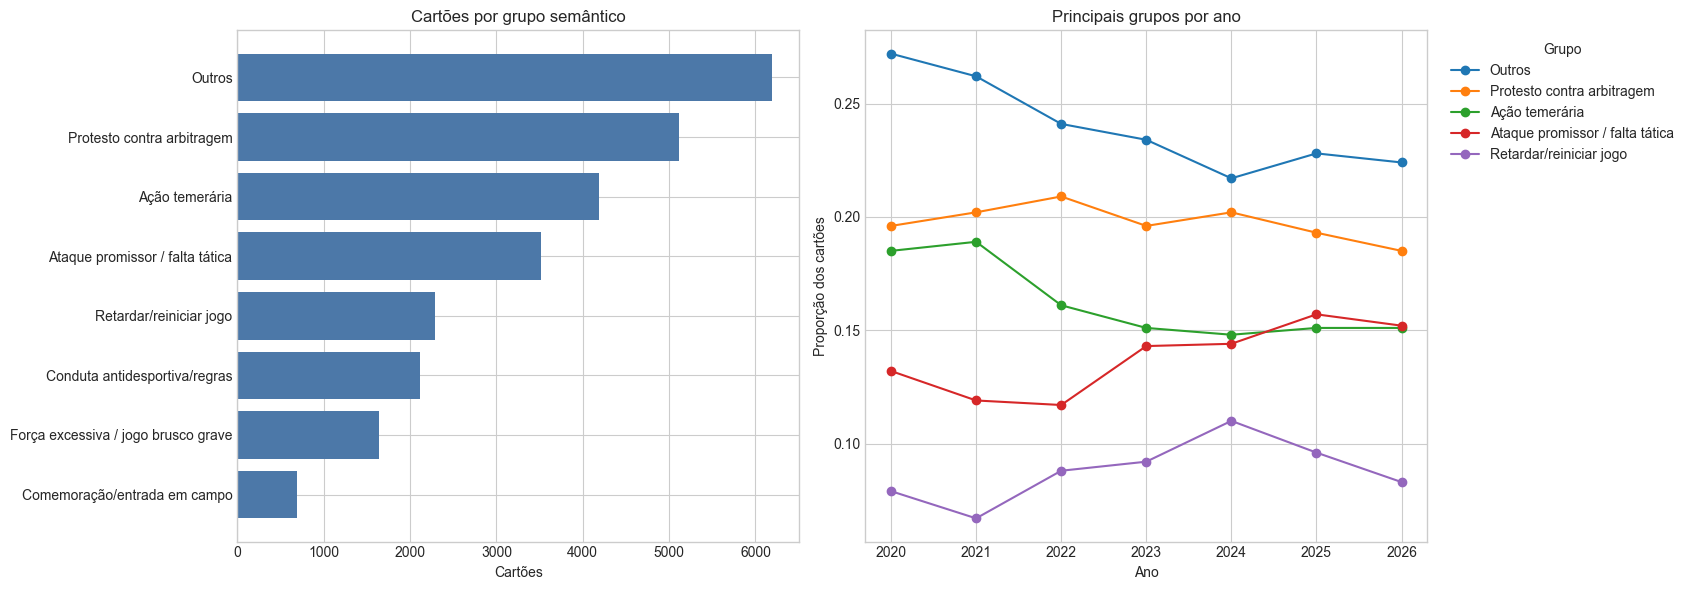

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
plot_card_summary = card_group_summary.sort_values("n_events", ascending=True)
axes[0].barh(plot_card_summary["card_reason_group"], plot_card_summary["n_events"], color="#4C78A8")
axes[0].set_title("Cartões por grupo semântico")
axes[0].set_xlabel("Cartões")
axes[0].set_ylabel("")

top_groups = card_group_summary.head(5)["card_reason_group"].tolist()
card_group_by_year[top_groups].plot(ax=axes[1], marker="o")
axes[1].set_title("Principais grupos por ano")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Proporção dos cartões")
axes[1].legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
save_plot(fig, "card_reason_groups_overview.png")
plt.show()

## **12. Motivos de Cartão por Time**

As tabelas abaixo contam os grupos de motivos para cada time que recebeu cartão. A tabela compacta mostra o grupo mais frequente por time; o gráfico mostra a composição proporcional dos grupos entre os times com mais cartões.


In [26]:
card_reason_by_team = (
    cards.groupby(["team", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
team_card_totals = cards.groupby("team").size().rename("total_cards")
card_reason_by_team = card_reason_by_team.merge(team_card_totals, on="team", how="left")
card_reason_by_team["pct_team_cards"] = (card_reason_by_team["n_events"] / card_reason_by_team["total_cards"]).round(4)
card_reason_by_team = card_reason_by_team.sort_values(["total_cards", "team", "n_events"], ascending=[False, True, False])

card_reason_top_by_team = (
    card_reason_by_team.sort_values(["team", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("team")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_team.head(30)

,team,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_team_cards
0,Red Bull Bragantino,Outros,265,264,1,59,999,0.2653
1,Fluminense,Outros,221,221,0,73,991,0.2230
2,Internacional,Outros,225,224,1,67,953,0.2361
3,São Paulo,Protesto contra arbitragem,231,187,44,93,950,0.2432
4,Palmeiras,Protesto contra arbitragem,216,172,44,100,937,0.2305
5,Corinthians,Outros,239,239,0,66,936,0.2553
6,Athletico Paranaense,Outros,210,210,0,69,883,0.2378
7,Atlético Mineiro,Outros,198,198,0,56,877,0.2258
8,Fortaleza Esporte Clube,Outros,182,182,0,50,851,0.2139
9,Flamengo,Outros,201,201,0,75,834,0.2410


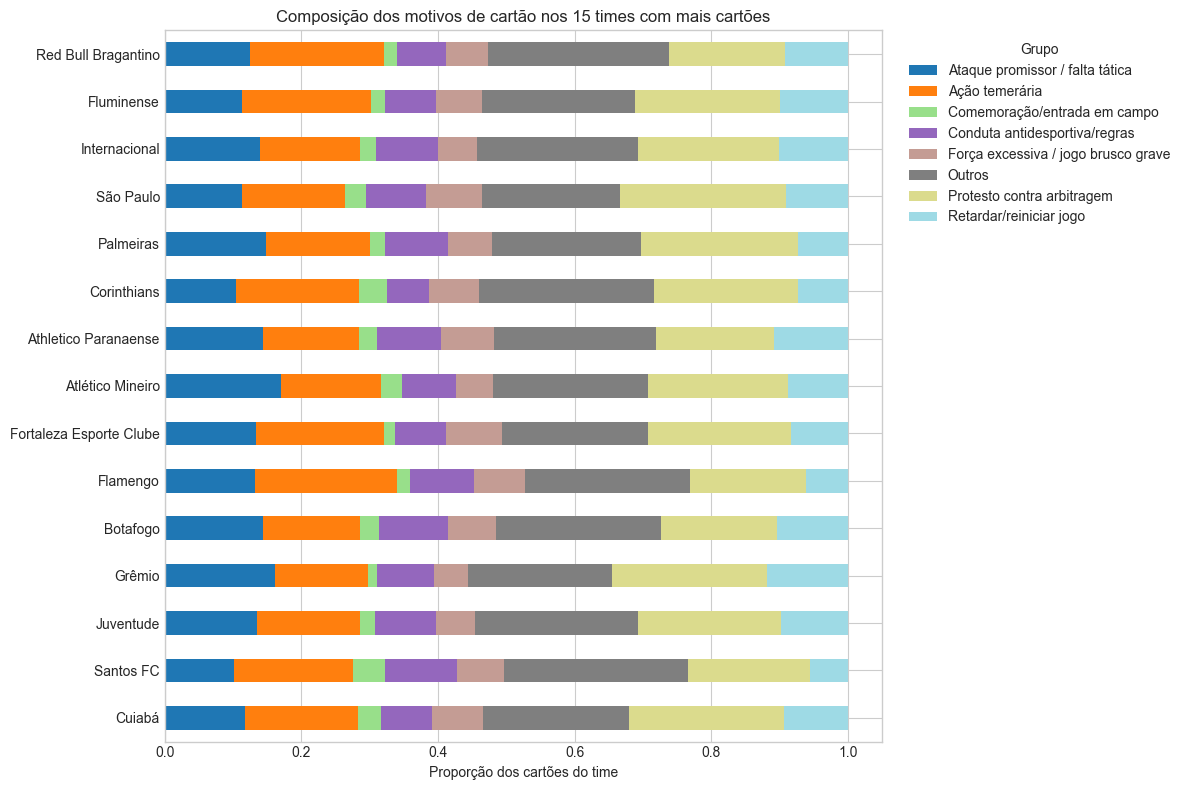

In [27]:
top_card_teams = cards["team"].value_counts().head(TOP_N_TEAMS).index
team_group_plot = pd.crosstab(
    cards.loc[cards["team"].isin(top_card_teams), "team"],
    cards.loc[cards["team"].isin(top_card_teams), "card_reason_group"],
    normalize="index",
).loc[top_card_teams]

fig, ax = plt.subplots(figsize=(12, 8))
team_group_plot.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
ax.invert_yaxis()
ax.set_title(f"Composição dos motivos de cartão nos {TOP_N_TEAMS} times com mais cartões")
ax.set_xlabel("Proporção dos cartões do time")
ax.set_ylabel("")
ax.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_plot(fig, "card_reason_groups_by_team.png")
plt.show()

## **13. Motivos de Cartão por Árbitro**

Aqui a unidade é o árbitro da partida. A tabela compacta mostra qual grupo de motivo aparece com mais frequência nos cartões registrados em jogos apitados por cada árbitro.


In [28]:
card_reason_by_referee = (
    cards.groupby(["arbitro", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
referee_card_totals = cards.groupby("arbitro").size().rename("total_cards")
card_reason_by_referee = card_reason_by_referee.merge(referee_card_totals, on="arbitro", how="left")
card_reason_by_referee["pct_referee_cards"] = (card_reason_by_referee["n_events"] / card_reason_by_referee["total_cards"]).round(4)
card_reason_by_referee = card_reason_by_referee.sort_values(["total_cards", "arbitro", "n_events"], ascending=[False, True, False])

card_reason_top_by_referee = (
    card_reason_by_referee.sort_values(["arbitro", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("arbitro")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_referee.head(30)

,arbitro,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_referee_cards
0,Braulio da Silva Machado,Outros,381,381,0,51,1178,0.3234
1,Wilton Pereira Sampaio,Outros,267,267,0,67,1078,0.2477
2,Bruno Arleu de Araujo,Outros,303,303,0,62,1037,0.2922
3,Ramon Abatti Abel,Outros,232,231,1,81,993,0.2336
4,Flavio Rodrigues de Souza,Protesto contra arbitragem,190,154,36,93,921,0.2063
5,Raphael Claus,Outros,229,229,0,59,911,0.2514
6,Anderson Daronco,Outros,225,225,0,60,909,0.2475
7,Felipe Fernandes de Lima,Outros,178,178,0,50,847,0.2102
8,Savio Pereira Sampaio,Outros,200,199,1,63,829,0.2413
9,Wagner do Nascimento Magalhaes,Outros,220,220,0,50,799,0.2753


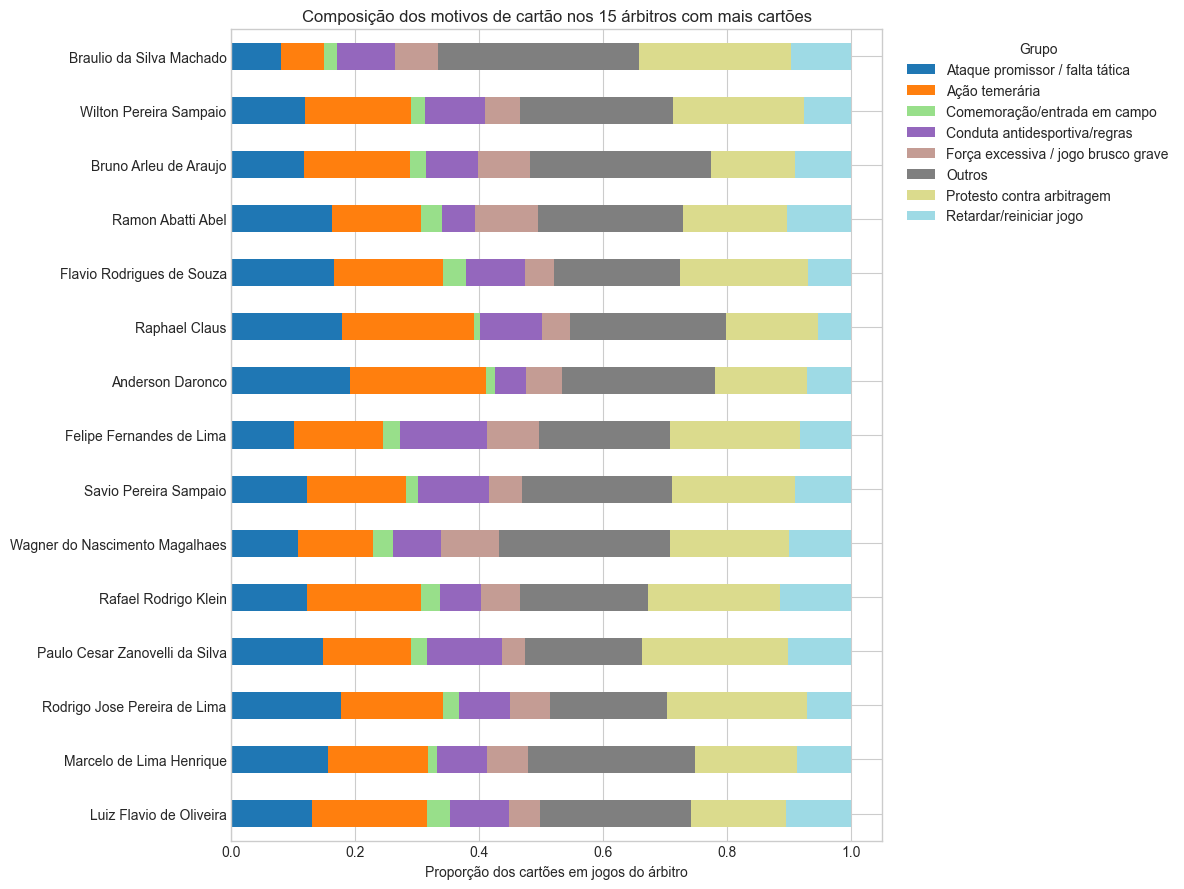

In [29]:
top_card_referees = cards["arbitro"].value_counts().head(TOP_N_REFEREES).index
referee_group_plot = pd.crosstab(
    cards.loc[cards["arbitro"].isin(top_card_referees), "arbitro"],
    cards.loc[cards["arbitro"].isin(top_card_referees), "card_reason_group"],
    normalize="index",
).loc[top_card_referees]

fig, ax = plt.subplots(figsize=(12, 9))
referee_group_plot.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
ax.invert_yaxis()
ax.set_title(f"Composição dos motivos de cartão nos {TOP_N_REFEREES} árbitros com mais cartões")
ax.set_xlabel("Proporção dos cartões em jogos do árbitro")
ax.set_ylabel("")
ax.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_plot(fig, "card_reason_groups_by_referee.png")
plt.show()

## **14. Busca Semântica nos Motivos de Cartão**

Esta célula permite testar consultas livres contra os textos únicos de justificativas. Ela é útil para auditar se expressões semelhantes ficaram próximas no espaço de embeddings.


In [30]:
def embed_query(text: str) -> np.ndarray:
    return np.asarray(embedding_model.encode([ENCODE_PREFIX_QUERY + text], normalize_embeddings=True))

def semantic_search_cards(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = embed_query(query)
    similarities = cosine_similarity(query_embedding, card_embeddings).ravel()
    result = card_text_counts.copy()
    result["similarity"] = similarities
    return result.sort_values("similarity", ascending=False)[[
        "similarity", "n_events", "card_reason_group", "bertopic_topic", "text_for_embedding",
    ]].head(top_k)

semantic_search_cards("reclamação contra arbitragem", top_k=10)

,similarity,n_events,card_reason_group,bertopic_topic,text_for_embedding
147,0.952177,21,Protesto contra arbitragem,-1,Por reclamação a arbitragem.
955,0.949411,4,Protesto contra arbitragem,-1,Reclamação contra a arbitragem.
447,0.948113,7,Protesto contra arbitragem,-1,Por reclamação contra a arbitragem.
4019,0.947529,1,Protesto contra arbitragem,-1,Por reclamar com a arbitragem.
4002,0.946994,1,Protesto contra arbitragem,-1,Por reclamacao contra arbitragem.
2410,0.946079,2,Protesto contra arbitragem,-1,Por reclamar da arbitragem.
4205,0.938707,1,Protesto contra arbitragem,-1,Por reclamar de forma acintosa com arbitragem.
4485,0.938624,1,Protesto contra arbitragem,-1,Reclamar com arbitragem.
613,0.936907,5,Protesto contra arbitragem,-1,Por reclamar contra a arbitragem.
3962,0.936571,1,Protesto contra arbitragem,-1,Por reclamar acintosamente com a arbitragem.


## **15. Motivos de Atraso/Acréscimos e VAR**

Os motivos de atraso/acréscimos são analisados separadamente dos cartões, com lógica mais simples: o único objetivo é identificar se há menção ao VAR na justificativa de acréscimo registrada pelo árbitro. Não são gerados embeddings para esses textos — a detecção é inteiramente léxica, via expressões regulares sobre os textos normalizados.

Os sinais buscados cobrem: siglas institucionais (`VAR`, `AVAR`, `VOR`, `ARA`), termos de processo (`checagem`, `revisão`, `review`) e referências a equipamentos (`\bmonitor\b`, `\bcabine\b`). Os padrões usam marcadores de fronteira de palavra para evitar falsos positivos em contextos médicos (e.g., *monitorar saúde do atleta*) ou em palavras que contenham as siglas por coincidência.

In [31]:
delay_text_counts = (
    delays[delays[DELAY_TEXT_COLUMN].ne("n/a")]
    .groupby("delay_reason_key")
    .agg(
        text_for_embedding=(DELAY_TEXT_COLUMN, "first"),
        n_games=(DELAY_TEXT_COLUMN, "size"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .reset_index()
    .sort_values("n_games", ascending=False)
    .reset_index(drop=True)
)
delay_text_counts.head(25)

,delay_reason_key,text_for_embedding,n_games,first_year,last_year
0,acrescimos devido as substituicoes e atendimento medico aos atletas,Acréscimos devido as substituições e atendimento médico aos atletas.,30,2020,2026
1,acrescimos devido substituicoes e transporte de atletas lesionados,Acréscimos devido substituições e transporte de atletas lesionados.,22,2020,2021
2,acrescimos devido a substituicoes atendimento medico e retirada de atletas supostamente lesionados do campo de jogo,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo.",14,2021,2023
3,acrescimos devido a substituicoes e atendimento de atletas supostamente lesionados,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .,13,2020,2025
4,acrescimos devido substituicoes atendimento medico aos atletas lesionados e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas.",13,2021,2025
5,acrescimos devido as substituicoes atendimento medico aos atletas e checagem do var,"Acréscimos devido as substituições, atendimento médico aos atletas e checagem do var.",12,2020,2022
6,nao houve atraso no inicio e reinicio de jogo acrescimos motivados por substituicoes e atendimento a jogadores supostamente lesionados,-nao houve atraso no inicio e reinicio de jogo.-acrescimos motivados por substituições e atendimento a jogadores supostamente lesionados.,11,2021,2025
7,acrescimos devido substituicoes atendimento medico aos atletas lesionados checagens do var e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados, checagens do var e paralisações diversas.",11,2023,2024
8,acrescimos devido substituicoes atendimento medico aos atletas lesionados e checagens do var,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e checagens do var.",11,2020,2022
9,acrescimos devido paralisacoes substituicoes e atendimento de atletas supostamente lesionados,"Acréscimos devido paralisações, substituições e atendimento de atletas supostamente lesionados.",10,2020,2024


In [32]:
delay_texts = delay_text_counts["text_for_embedding"].tolist()
delay_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in delay_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
delay_embeddings = np.asarray(delay_embeddings)
print(f"Embeddings de atrasos/acréscimos: {delay_embeddings.shape}")

Batches: 100%|██████████| 59/59 [01:13<00:00,  1.25s/it]

Embeddings de atrasos/acréscimos: (3764, 1024)


In [34]:
delay_topic_model = make_topic_model(DELAY_MIN_TOPIC_SIZE)
delay_topics, _ = delay_topic_model.fit_transform(delay_texts, embeddings=delay_embeddings)
delay_text_counts["bertopic_topic"] = delay_topics

delay_text_counts_for_summary = delay_text_counts.rename(columns={"n_games": "n_events"})
delay_topic_summary = build_topic_summary(delay_topic_model, delay_text_counts_for_summary, "bertopic_topic")
delay_topic_summary.head(20)

,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,0,879,0_substituições_acréscimos_atendimento_atletas,"[substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições, substituições atendimento, atletas supostamente]","[Acréscimos devido à substituições e atendimento à atletas supostamente lesionados., Acréscimos para substituições e atendimento a atletas supostamente lesionados., Acréscimos devido as substituições e atendimento de...",879,1458,"substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições"
1,1,434,1_homenagem_silêncio_respeitado_silêncio homenagem,"[homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, respeitado silêncio, acréscimos, substituições, covid]","[Acréscimos motivados por, substituições, atendimento e retirada de atletas supostamente lesionados e checagem var.foi respeitado um minuto de silêncio em homenagem as vítimas do covid 19., Acréscimos devido a substi...",434,635,"homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, respeitado silêncio, acréscimos"
2,-1,411,-1_atraso_ilustre_torcedor_fluminense,"[atraso, ilustre, torcedor, fluminense, flamengo, substituições, informo, lesionados, entrada, acréscimos]","[Atraso no reinício da partida, devido a entrada tardia de ambas as equipes. informo que foi realizado pelo quarto árbitro e o assistente 02 o procedimento de ida aos vestiários. acréscimos devido a parada médica par...",411,588,outliers
3,2,370,2_não_não houve_houve_não houve atraso,"[não, não houve, houve, não houve atraso, houve atraso, acréscimos, substituições, atrasos, atrasos acréscimos, houve atraso acréscimos]","[Não houve atraso. acréscimos por substituições e retirada de atletas supostamente lesionados., Não houve atraso. acréscimos devido a substituições, atendimento de atletas supostamente lesionados e reposição de bola....",370,542,"não, não houve, houve, não houve atraso, houve atraso, acréscimos, substituições, atrasos"
4,3,282,3_não houve_não_houve_homenagem,"[não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma, homenagem póstuma, respeitado]","[Não houve atrasos. acréscimos devido as substituições, retirada de atletas supostamente lesionados e reposição de bola.informo que antes da partida foi respeitado um minuto de silêncio em homenagem póstuma as vitima...",282,451,"não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma"
5,4,259,4_homenagem_silêncio_respeitado_covid,"[homenagem, silêncio, respeitado, covid, 19, covid 19, silêncio homenagem, acréscimos, substituições, 19 acréscimos]","[Foi respeitado 1 minuto de silêncio em homenagem as vitimas da covid 19.acréscimos devido a substituições e atendimento de atletas supostamente lesionados., Foi respeitado um minuto de silêncio em homenagem póstuma ...",259,345,"homenagem, silêncio, respeitado, covid, 19, covid 19, silêncio homenagem, acréscimos"
6,5,224,5_atraso_entrada_reinício_equipes,"[atraso, entrada, reinício, equipes, acréscimos, ambas, informo, substituições, ambas equipes, segundo]","[Houve atraso no inicio da partida de 02 minutos devido ao atraso de ambas as equipes.acréscimos devido atendimento a atletas supostamente lesionados, reposição de bola e substituições., Informo que ambas as equipes ...",224,290,"atraso, entrada, reinício, equipes, acréscimos, ambas, informo, substituições"
7,6,188,6_primeiro_segundo_primeiro segundo_acréscimos primeiro,"[primeiro, segundo, primeiro segundo, acréscimos primeiro, segundo paralisações substituições, segundo paralisações, substituições, lesionados, atendimento, paralisações substituições]","[Acréscimos de 6 minutos no primeiro tempo, e 8 minutos no segundo tempo devido a paralisações, substituições, atendimento a atletas lesionados e checagem do var., Acréscimos de 4 minutos no primeiro 

In [36]:
delay_topic_examples = top_examples_by_topic(
    delay_text_counts.rename(columns={"n_games": "n_events"}),
    "bertopic_topic",
    top_n=5,
).rename(columns={"n_events": "n_games"})
delay_topic_examples.head(30)

,bertopic_topic,n_games,text_for_embedding
0,-1,2,"- acrescimos devido substituições , retirada de atletas do campo e revisões na ara.- concedido um minuto de silencio em homenagem postuma ao sr denis leitao de castro."
1,-1,2,* acrescimos devido substituições e retirada de atletas do campo de jogo.* concedido um minuto de silencio em homenagem postuma as vitimas da covid19.
2,-1,2,Acréscimos devidos as substituições e atendimentos médico aos atletas lesionados.informo que a partida inicio com 2 minutos de atraso devido ao atraso de são paulo futebol clube de 3 minutos e da equipe saf botafogo ...
3,-1,2,"Acréscimos motivados por substituições, atendimento a atletas supostamente lesionados e revisões var.foi respeitado um minutos de silêncio em homenagem póstuma aos senhores marcelo figueira, lucas oliveira azevedo, m..."
4,-1,2,"Acréscimos motivados em recuperar o tempo perdido por substituições, entrada da maca ao campo de jogo para atendimentos médicos e reposições de bola em jogo.foi respeitado um minuto de silencio em homenagem póstuma a..."
5,0,30,Acréscimos devido as substituições e atendimento médico aos atletas.
6,0,22,Acréscimos devido substituições e transporte de atletas lesionados.
7,0,14,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo."
8,0,13,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .
9,0,13,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas."


In [33]:
VAR_SIGNAL_PATTERNS = {
    "var": r"\bvar\b",
    "avar": r"\bavar\b",
    "vor": r"\bvor\b|sala\s+vor",
    "ara": r"\bara\b",
    "arbitro_de_video": r"arbitro\s+de\s+video|arbitragem\s+de\s+video|video\s+arbitro",
    "checagem": r"checag(?:em|ens)|checando|checar",
    "revisao": r"revis(?:ao|oes|ar|ado|ada)|review",
    "monitor_cabine": r"\bmonitor\b|\bcabine\b",
}

def detect_var_signals(text: str) -> tuple[bool, str]:
    normalized = normalize_text(text)
    matches = [name for name, pattern in VAR_SIGNAL_PATTERNS.items() if re.search(pattern, normalized)]
    return bool(matches), ", ".join(matches)

var_detection = delays[DELAY_TEXT_COLUMN].apply(detect_var_signals)
delays["var_used"] = var_detection.map(lambda item: item[0])
delays["var_signal"] = var_detection.map(lambda item: item[1])

var_summary = pd.Series({
    "games_total": len(delays),
    "games_with_var_signal": int(delays["var_used"].sum()),
    "pct_with_var_signal": round(delays["var_used"].mean(), 4),
})
var_summary

games_total              5663.0000
games_with_var_signal    2031.0000
pct_with_var_signal         0.3586
dtype: float64

In [35]:
signal_counts = {}
for signal_name, pattern in VAR_SIGNAL_PATTERNS.items():
    signal_counts[signal_name] = delays[DELAY_TEXT_COLUMN].apply(
        lambda t, p=pattern: bool(re.search(p, normalize_text(str(t))))
    ).sum()

signal_dist = pd.Series(signal_counts, name='partidas').sort_values(ascending=False)
print('Frequência de cada sinal VAR:')
print(signal_dist.to_string())

only_monitor = (
    delays[delays['var_signal'].eq('monitor_cabine')]
    [[DELAY_TEXT_COLUMN, 'year']]
    .drop_duplicates(DELAY_TEXT_COLUMN)
    .sort_values('year')
    .reset_index(drop=True)
)
print(f'\nTextos ativados exclusivamente por monitor_cabine: {len(only_monitor)}')
print('Revisar manualmente para estimar precisão do detector neste sinal.')
only_monitor.head(15)

Frequência de cada sinal VAR:
var                 1745
checagem            1512
revisao              561
ara                  136
arbitro_de_video      79
vor                   48
monitor_cabine        36
avar                   2

Textos ativados exclusivamente por monitor_cabine: 1
Revisar manualmente para estimar precisão do detector neste sinal.


,delay_reason_clean,year
0,"Não houve atraso. os acréscimos foram dados por reposição da bola em jogo, gols, substituições atendimento ao goleiro mandante, tempo de cabine e retirada de atletas para atendimento.",2023


In [37]:
delay_var_by_year = (
    delays.groupby("year")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
    )
    .reset_index()
)
delay_var_by_year["pct_with_var_signal"] = (
    delay_var_by_year["games_with_var_signal"] / delay_var_by_year["games"]
).round(4)
delay_var_by_year

,year,games,games_with_var_signal,pct_with_var_signal
0,2020,880,211,0.2398
1,2021,882,375,0.4252
2,2022,882,340,0.3855
3,2023,882,347,0.3934
4,2024,882,325,0.3685
5,2025,882,326,0.3696
6,2026,373,107,0.2869


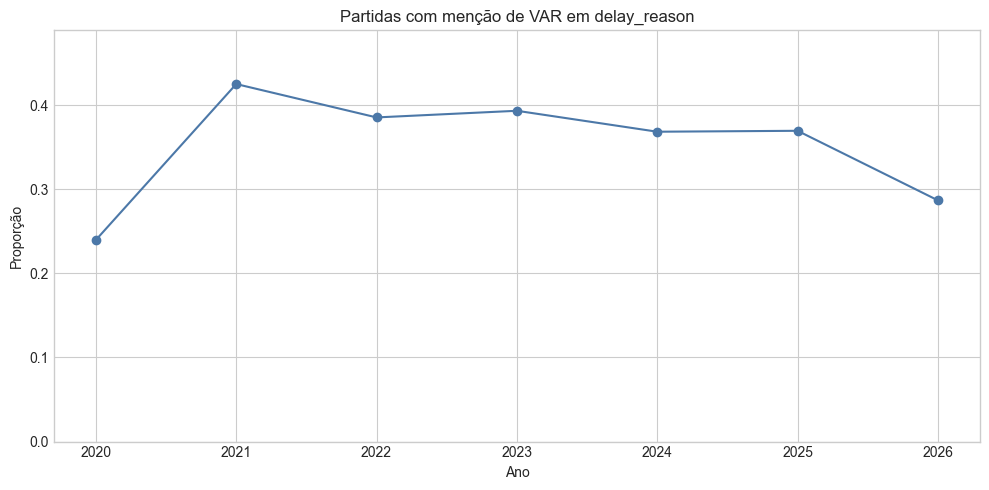

In [38]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(delay_var_by_year["year"], delay_var_by_year["pct_with_var_signal"], marker="o", color="#4C78A8")
ax.set_title("Partidas com menção de VAR em delay_reason")
ax.set_xlabel("Ano")
ax.set_ylabel("Proporção")
ax.set_ylim(0, max(0.05, delay_var_by_year["pct_with_var_signal"].max() * 1.15))
plt.tight_layout()
save_plot(fig, "var_mentions_by_year.png")
plt.show()

In [39]:
var_examples = (
    delays[delays["var_used"]]
    .sort_values(["year", "round", "game_number"])
    [["year", "round", "home_team", "away_team", "arbitro", "var_signal", DELAY_TEXT_COLUMN]]
    .head(25)
)
var_examples

,year,round,home_team,away_team,arbitro,var_signal,delay_reason_clean
10,2020,1,Santos FC,Red Bull Bragantino,Ricardo Marques Ribeiro,"var, checagem",Não houve atraso no inicio e reinicio do jogo. foi cumprido a diretriz técnica operacional da cbf de entrada das equipes 05 (cinco) minutos antes do jogo para equipe local (15:55) e 04 (quatro) minutos antes do jogo ...
19,2020,1,Sport Recife,Ceará,Edina Alves Batista,"var, checagem","Não houve atraso. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (20:55) e 4 (quatro) minutos antes do jogo para equipe visitante (20:56)..."
25,2020,1,Fortaleza Esporte Clube,Athletico Paranaense,Braulio da Silva Machado,"var, checagem","Não houve atraso no início e reinício de jogo. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (18:55) e 4 (quatro) minutos antes do jogo ..."
74,2020,2,Vasco da Gama,Sport Recife,Rodolpho Toski Marques,"var, revisao","Não houve atraso no início e reinício de jogo.foram acrescidos 2 minutos no primeiro tempo e 8 minutos no segundo tempo devido as substituições, reposição de bola em jogo, avaliação médica dos atletas supostamente le..."
83,2020,2,Atlético Mineiro,Corinthians,Wagner do Nascimento Magalhaes,var,"Não houve atraso no início e reinício da partida.acréscimos devido substituições,atendimento à atletas supostamente lesionados,reposição de bola em jogo e var.houve 01 minuto de silêncio em homenagem às vitimas do co..."
92,2020,2,Athletico Paranaense,Goiás,Diego Pombo Lopez,"var, checagem","Acréscimos no primeiro tempo devido a atendimento e retirada pela ambulância do atleta número 55 do athlético e também por checagens do var. acréscimos no segundo tempo devido a substituições, retirada de atletas sup..."
98,2020,2,Atlético,Flamengo,Luiz Flavio de Oliveira,"var, checagem","Não houve atrasos.acréscimos motivados por, atendimento médico, substituições, reposição de bola em jogo e checagem do var.informo que na relação nominal de atletas da equipe atletico cg, constava que o uniforme do g..."
120,2020,3,Fluminense,Internacional,Raphael Claus,"var, revisao","Não houve atraso no início e reinício da partida. houve acréscimos no primeiro e no segundo tempo de partida, devido as substituições, revisões do var, reposições de bola em jogo e atendimentos aos atletas supostamen..."
126,2020,3,Santos FC,Athletico Paranaense,Anderson Daronco,"var, checagem","Acréscimos de 4 minutos no primeiro tempo e 5 minutos no segundo tempo devido à paralisações, substituições, atendimento a atletas lesionados e checagem do var."
132,2020,3,Esporte Clube Bahia,Red Bull Bragantino,Felipe Fernandes de Lima,"var, checagem","Acréscimos devido as paralisações para retirada de atletas supostamente lesionados do campo de jogo, substituições e recuperação de tempo perdido por checagem do var.informo que foi respeitado um minuto de silêncio e..."


## **16. Uso de VAR por Time e por Árbitro**

Para times, a contagem considera partidas em que o time aparece como mandante ou visitante. Para árbitros, a contagem considera as partidas registradas em `delay_reasons`. Em ambos os casos, `var_used` significa presença de sinal textual de VAR no campo de atraso/acréscimos, não uma validação externa do protocolo da partida.


In [40]:
def most_common_non_empty(values: pd.Series) -> str:
    cleaned = values.astype(str).str.strip()
    cleaned = cleaned[cleaned.ne("")]
    if cleaned.empty:
        return ""
    return cleaned.value_counts().idxmax()

delay_home_games = delays.rename(columns={"home_team": "team", "away_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_away_games = delays.rename(columns={"away_team": "team", "home_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_team_games = pd.concat([delay_home_games, delay_away_games], ignore_index=True)

delay_var_by_team = (
    delay_team_games.groupby("team")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_team["pct_with_var_signal"] = (
    delay_var_by_team["games_with_var_signal"] / delay_var_by_team["games"]
).round(4)
delay_var_by_team = delay_var_by_team.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_team.head(30)

,team,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Red Bull Bragantino,456,174,"var, checagem",0.3816
1,Flamengo,443,189,"var, checagem",0.4266
2,Corinthians,442,194,"var, checagem",0.4389
3,Fluminense,442,173,"var, checagem",0.3914
4,Palmeiras,426,196,"var, checagem",0.4601
5,Internacional,417,177,"var, checagem",0.4245
6,Athletico Paranaense,398,170,"var, checagem",0.4271
7,São Paulo,396,207,"var, checagem",0.5227
8,Atlético Mineiro,396,146,"var, checagem",0.3687
9,Fortaleza Esporte Clube,368,158,"var, checagem",0.4293


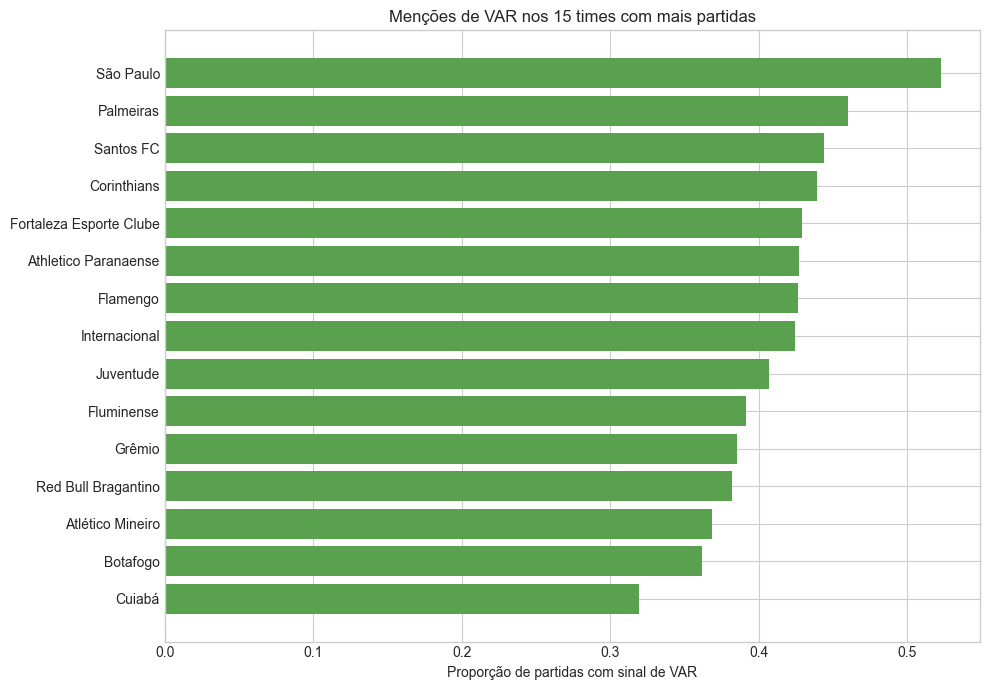

In [41]:
top_var_teams = delay_var_by_team.head(TOP_N_TEAMS).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_var_teams["team"], top_var_teams["pct_with_var_signal"], color="#59A14F")
ax.set_title(f"Menções de VAR nos {TOP_N_TEAMS} times com mais partidas")
ax.set_xlabel("Proporção de partidas com sinal de VAR")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "var_mentions_by_team.png")
plt.show()

In [42]:
delay_var_by_referee = (
    delays.groupby("arbitro")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_referee["pct_with_var_signal"] = (
    delay_var_by_referee["games_with_var_signal"] / delay_var_by_referee["games"]
).round(4)
delay_var_by_referee = delay_var_by_referee.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_referee.head(30)

,arbitro,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Anderson Daronco,255,83,"var, checagem",0.3255
1,Raphael Claus,243,80,"var, checagem",0.3292
2,Ramon Abatti Abel,233,102,"var, checagem",0.4378
3,Wilton Pereira Sampaio,223,103,"var, checagem",0.4619
4,Braulio da Silva Machado,222,131,"var, checagem",0.5901
5,Flavio Rodrigues de Souza,217,94,"var, checagem",0.4332
6,Bruno Arleu de Araujo,205,87,"var, checagem",0.4244
7,Savio Pereira Sampaio,190,80,"var, checagem",0.4211
8,Marcelo de Lima Henrique,175,67,"var, checagem",0.3829
9,Wagner do Nascimento Magalhaes,165,59,"var, checagem",0.3576


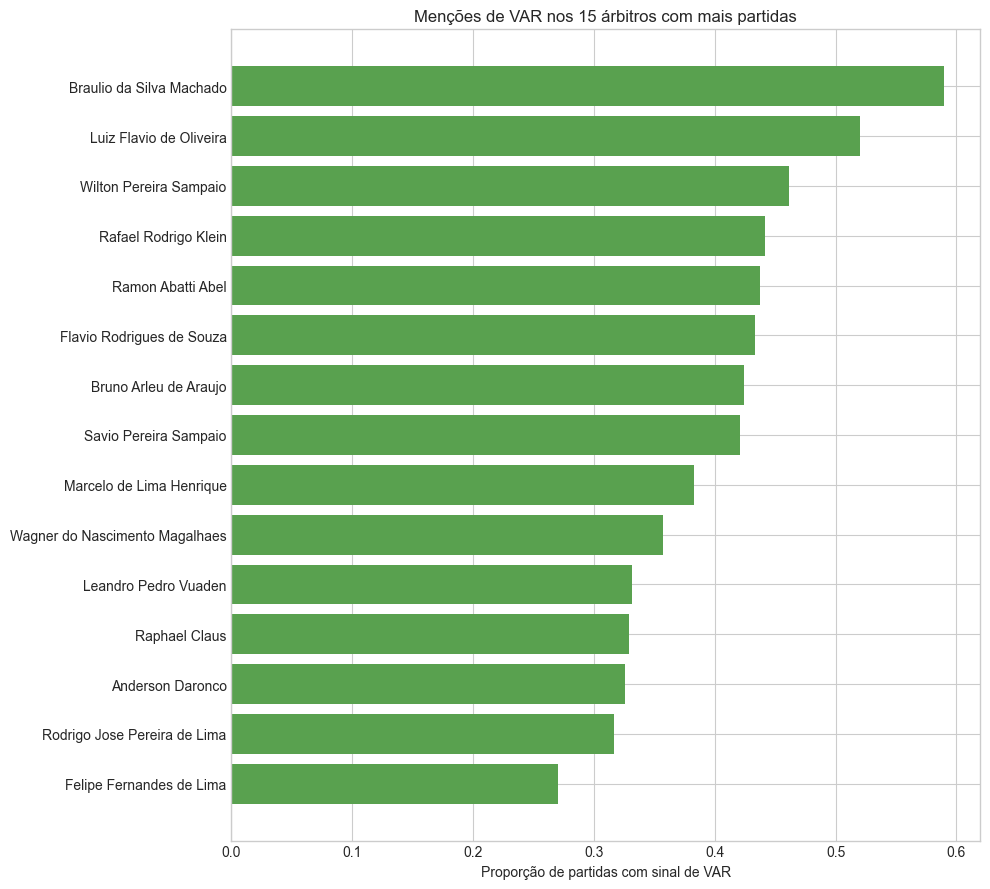

In [43]:
top_var_referees = delay_var_by_referee.head(TOP_N_REFEREES).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top_var_referees["arbitro"], top_var_referees["pct_with_var_signal"], color="#59A14F")
ax.set_title(f"Menções de VAR nos {TOP_N_REFEREES} árbitros com mais partidas")
ax.set_xlabel("Proporção de partidas com sinal de VAR")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "var_mentions_by_referee.png")
plt.show()

## **17. Salvamento dos Artefatos**

Os arquivos salvos mantêm os artefatos de modelagem e acrescentam tabelas analíticas por time e por árbitro. Assim, a leitura final não depende apenas dos gráficos do notebook.


In [44]:
outros_audit = (
    cards[cards["card_reason_group"].eq("Outros")]
    .groupby(CARD_TEXT_COLUMN)
    .size()
    .reset_index(name="n_events")
    .sort_values("n_events", ascending=False)
)

card_topic_summary_path = CARD_OUTPUT_DIR / "card_bertopic_topic_summary.csv"
card_topic_examples_path = CARD_OUTPUT_DIR / "card_bertopic_topic_examples.csv"
card_unique_topics_path = CARD_OUTPUT_DIR / "card_reason_unique_topics_labels.csv"
card_labeled_path = CARD_OUTPUT_DIR / "card_reasons_with_labels.csv"
card_group_summary_path = CARD_OUTPUT_DIR / "card_reason_group_summary.csv"
card_group_by_year_path = CARD_OUTPUT_DIR / "card_reason_group_by_year.csv"
card_group_by_type_path = CARD_OUTPUT_DIR / "card_reason_group_by_card_type.csv"
card_reason_by_team_path = CARD_OUTPUT_DIR / "card_reason_by_team.csv"
card_reason_top_by_team_path = CARD_OUTPUT_DIR / "card_reason_top_by_team.csv"
card_reason_by_referee_path = CARD_OUTPUT_DIR / "card_reason_by_referee.csv"
card_reason_top_by_referee_path = CARD_OUTPUT_DIR / "card_reason_top_by_referee.csv"
outros_audit_path = CARD_OUTPUT_DIR / "card_reason_outros_audit.csv"

delay_topic_summary_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_summary.csv"
delay_topic_examples_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_examples.csv"
delay_unique_topics_path = DELAY_OUTPUT_DIR / "delay_reason_unique_topics.csv"
delay_labeled_path = DELAY_OUTPUT_DIR / "delay_reasons_with_var.csv"
delay_var_by_year_path = DELAY_OUTPUT_DIR / "delay_var_by_year.csv"
delay_var_by_team_path = DELAY_OUTPUT_DIR / "delay_var_by_team.csv"
delay_var_by_referee_path = DELAY_OUTPUT_DIR / "delay_var_by_referee.csv"

card_topic_summary.to_csv(card_topic_summary_path, index=False)
card_topic_examples.to_csv(card_topic_examples_path, index=False)
card_text_counts.to_csv(card_unique_topics_path, index=False)
cards.to_csv(card_labeled_path, index=False)
card_group_summary.to_csv(card_group_summary_path, index=False)
card_group_by_year.to_csv(card_group_by_year_path)
card_group_by_type.to_csv(card_group_by_type_path)
card_reason_by_team.to_csv(card_reason_by_team_path, index=False)
card_reason_top_by_team.to_csv(card_reason_top_by_team_path, index=False)
card_reason_by_referee.to_csv(card_reason_by_referee_path, index=False)
card_reason_top_by_referee.to_csv(card_reason_top_by_referee_path, index=False)
outros_audit.to_csv(outros_audit_path, index=False)

delay_topic_summary.to_csv(delay_topic_summary_path, index=False)
delay_topic_examples.to_csv(delay_topic_examples_path, index=False)
delay_text_counts.to_csv(delay_unique_topics_path, index=False)
delays.to_csv(delay_labeled_path, index=False)
delay_var_by_year.to_csv(delay_var_by_year_path, index=False)
delay_var_by_team.to_csv(delay_var_by_team_path, index=False)
delay_var_by_referee.to_csv(delay_var_by_referee_path, index=False)

output_paths = [
    card_topic_summary_path,
    card_topic_examples_path,
    card_unique_topics_path,
    card_labeled_path,
    card_group_summary_path,
    card_group_by_year_path,
    card_group_by_type_path,
    card_reason_by_team_path,
    card_reason_top_by_team_path,
    card_reason_by_referee_path,
    card_reason_top_by_referee_path,
    outros_audit_path,
    delay_topic_summary_path,
    delay_topic_examples_path,
    delay_unique_topics_path,
    delay_labeled_path,
    delay_var_by_year_path,
    delay_var_by_team_path,
    delay_var_by_referee_path,
]

print("Arquivos salvos:")
for output_path in output_paths:
    print(f"  {output_path}")

Arquivos salvos:
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_examples.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_unique_topics_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reasons_with_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_year.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_card_type.csv
  /Users/gcarninatto/D